In [42]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import numba
import torch
from torch import nn 
from torch.optim import RAdam
from scipy.special import softmax
import h5py
import yaml
import argparse

import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime
vector.register_numba()
vector.register_awkward()
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import mplhep as hep
hep.style.use(hep.style.ROOT)

from importlib import reload
from sklearn.preprocessing import QuantileTransformer
from copy import deepcopy
import numpy as np
from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin
from multiprocessing import Pool, cpu_count
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

In [2]:
dctr_input = "/eos/home-g/gbonomel/tth/dctr/training_datasets/btag_shapes/for_inference/dataset_dctr_4j3b_withsignal_allyears_baseline.parquet"
spanet_model = "/eos/home-g/gbonomel/tth/spanet/models/singlewp_dctr_leptonveto_medium/spanet_evaluation/spanet_onnx_inference.parquet"
event_f = "/eos/home-g/gbonomel/tth/spanet/models/training_dec25/event.yaml"
dctr_model = "/eos/home-g/gbonomel/tth/dctr/plot_input_variables/model_adv_epoch40.pth"
save_folder = "/eos/home-g/gbonomel/projects/www/dctr"

# ensure save folder exists
os.makedirs(save_folder, exist_ok=True)

CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

In [3]:
labels = {
    "tthbb": 1,
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    "ttv": 5,
    "singletop": 6
}

In [4]:
tthbb_transformed_min = 0.5
tthbb_transformed_max = 0.8
ttlf_max = 0.5

In [5]:
def get_cr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb"] >= tthbb_transformed_min) &
        (scores["tthbb"] < tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask 

def get_sr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb"] >= tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask

In [6]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution

    def save(self, filename):
        np.savez(
            filename,
            quantiles=self.quantiles_,
            reference_quantiles=self.reference_quantiles_,
            n_quantiles=self.n_quantiles,
            output_distribution=self.output_distribution,
        )

    def load(self, filename):
        data = np.load(filename)
        self.quantiles_ = data["quantiles"]
        self.reference_quantiles_ = data["reference_quantiles"]
        self.n_quantiles = int(data["n_quantiles"])
        self.output_distribution = str(data["output_distribution"])
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

In [7]:
# Simple DNN Class Definition (must match training)
class DCTRNet(nn.Module):
    def __init__(self, input_dim, hidden_net=[64,64,64], hidden_net_classifier=[64,64], hidden_net_adv=[64,64]):
        super(DCTRNet, self).__init__()
        layers = []
        for h_dim in hidden_net:
            layers.append(nn.Linear(input_dim, h_dim))
            layers.append(nn.ReLU())
            input_dim = h_dim

        layers.append(nn.Linear(input_dim, input_dim))
        self.pre_model = nn.Sequential(*layers)
        self.features_dim = hidden_net[-1]

        input_dim = self.features_dim
        layers_classifier = []
        for h_dim in hidden_net_classifier:
            layers_classifier.append(nn.Linear(input_dim, h_dim))
            layers_classifier.append(nn.ReLU())
            input_dim = h_dim
        layers_classifier.append(nn.Linear(input_dim, 1))
        self.classifier = nn.Sequential(*layers_classifier)

        input_dim = self.features_dim
        adv_layers = []
        for h_dim in hidden_net_adv:
            adv_layers.append(nn.Linear(input_dim, h_dim))
            adv_layers.append(nn.ReLU())
            input_dim = h_dim
        adv_layers.append(nn.Linear(input_dim, 1))
        self.model_adv = nn.Sequential(*adv_layers)
    
    def forward(self, x, return_features=False, run_adv=False):
        features = self.pre_model(x)
        if run_adv:
            adv_output = self.model_adv(features)
            if return_features:
                return adv_output, features
            return adv_output
        else:
            if return_features:
                return self.classifier(features), features
            return self.classifier(features)

Open the spanet output to get spanet scores and weights. Add the spanet scores as a field to the DCTR parquet data frame

In [8]:
# load the dctr model and dctr inputs
df = ak.from_parquet(dctr_input)
spanet_out = ak.from_parquet(spanet_model)

In [9]:
# extract weights by event
weights = ak.to_numpy(df.event.weight)

In [28]:
njet = ak.num(df.JetGood)

In [10]:
# true labels from dctr input to use as mask by sample
true_labels = {}
for label in labels:
    true_labels[label] = ak.to_numpy(df[f"{label}"]).astype(bool)
true_labels

{'tthbb': array([False, False, False, ..., False, False, False]),
 'ttbb': array([False, False, False, ..., False,  True, False]),
 'ttcc': array([False, False, False, ..., False, False, False]),
 'ttlf': array([ True,  True,  True, ...,  True, False,  True]),
 'ttv': array([False, False, False, ..., False, False, False]),
 'singletop': array([False, False, False, ..., False, False, False])}

In [11]:
# convert spanet output into numpy arrays without masked arrays
pred_labels = {}
for key in spanet_out.fields:
    pred_labels[key] = ak.to_numpy(ak.fill_none(spanet_out[key], 0.0))
pred_labels

{'tthbb': array([0.01677565, 0.02462359, 0.10016861, ..., 0.02080909, 0.26315096,
        0.08540645]),
 'ttbb': array([0.04531126, 0.07313527, 0.09297699, ..., 0.04560841, 0.34171772,
        0.14383087]),
 'ttcc': array([0.10255951, 0.17910963, 0.10449398, ..., 0.23260058, 0.02688115,
        0.26112619]),
 'ttlf': array([0.24880981, 0.26536328, 0.104104  , ..., 0.5371269 , 0.02242004,
        0.24478647]),
 'ttv': array([0.21260256, 0.20786221, 0.51113534, ..., 0.02679482, 0.20191857,
        0.02492064]),
 'singletop': array([0.37394121, 0.24990599, 0.08712104, ..., 0.13706021, 0.14391163,
        0.23992936]),
 'weight': array([-0.05854146, -0.06429805, -0.02314291, ..., -0.01669056,
         0.0378209 , -0.14732438])}

In [12]:
# transform the tthbb score with quantile transformation
is_tthbb = true_labels["tthbb"]
score_tthbb = ak.to_numpy(pred_labels["tthbb"][is_tthbb])
weights_tthbb = weights[is_tthbb]
pred_labels_transformed = deepcopy(pred_labels)
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
transformer.fit(score_tthbb, sample_weight=weights_tthbb)
pred_labels_transformed["tthbb"] = transformer.transform(pred_labels["tthbb"])

In [13]:
# add the spanet output to the df 
spanet_fields = {key: pred_labels_transformed[key] for key in pred_labels_transformed.keys()}
df = ak.with_field(df, ak.zip(spanet_fields), "spanet_output")
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'tthbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'ttv',
 'singletop',
 'vv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event',
 'spanet_output']

In [14]:
df.spanet_output.fields

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttv', 'singletop', 'weight']

In [15]:
df # contains all regions 

<Array [{JetGood: [, ... weight: -0.147}}] type='9464135 * {"JetGood": var * {"p...'>

In [16]:
# dctr input variables
data = []
bjet_pt_3 = df.BJetGood.pt[:,2]
bjet_eta_3 = df.BJetGood.eta[:,2]
for f in df.events.fields:
    data.append(ak.to_numpy(df.events[f]))
data.append(ak.to_numpy(bjet_pt_3))
data.append(ak.to_numpy(bjet_eta_3))
dctr_inputs = np.stack(data).T

In [17]:
dctr_inputs.shape # contains all regions

(9464135, 12)

In [18]:
# std normalize the dctr inputs (mean 0 std 1) before converting to tensor
scaler = StandardScaler()
x_scaled = scaler.fit_transform(dctr_inputs.astype(np.float32))
x_tensor = torch.from_numpy(x_scaled)

In [20]:
# Initialize the model with the same architecture as training
model = DCTRNet(input_dim=x_tensor.shape[1], hidden_net=[64,32], 
                         hidden_net_classifier=[32,32], hidden_net_adv=[16,16]).to("cpu")

# load already existing model
model_path = dctr_model 
if os.path.exists(model_path):
    checkpoint = torch.load(model_path, map_location=torch.device('cpu'))
    if isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
         model.load_state_dict(checkpoint['state_dict']) # incase it was saved wrapped
    else:
         model.load_state_dict(checkpoint)
    print(f"Loaded model from {model_path}")
else:
    print(f"Model file not found at {model_path}")

model.eval()

with torch.no_grad():
   inputs = x_tensor.to('cpu')
   outputs = model(inputs)
   # Apply sigmoid for probability output
   predictions = torch.sigmoid(outputs).squeeze().cpu()

/tmp/gbonomel/ipykernel_3318527/86563100.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location=torch.device('cpu'))


Loaded model from /eos/home-g/gbonomel/tth/dctr/plot_input_variables/model_adv_epoch40.pth


In [21]:
dctr_score = predictions.cpu().detach().numpy()
dctr_w_ttbb = dctr_score / (1 - dctr_score)

In [22]:
# add dctr score and weight to the df
df = ak.with_field(df, dctr_score, "dctr_score")
df = ak.with_field(df, dctr_w_ttbb, "dctr_weight")
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'tthbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'ttv',
 'singletop',
 'vv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event',
 'spanet_output',
 'dctr_score',
 'dctr_weight']

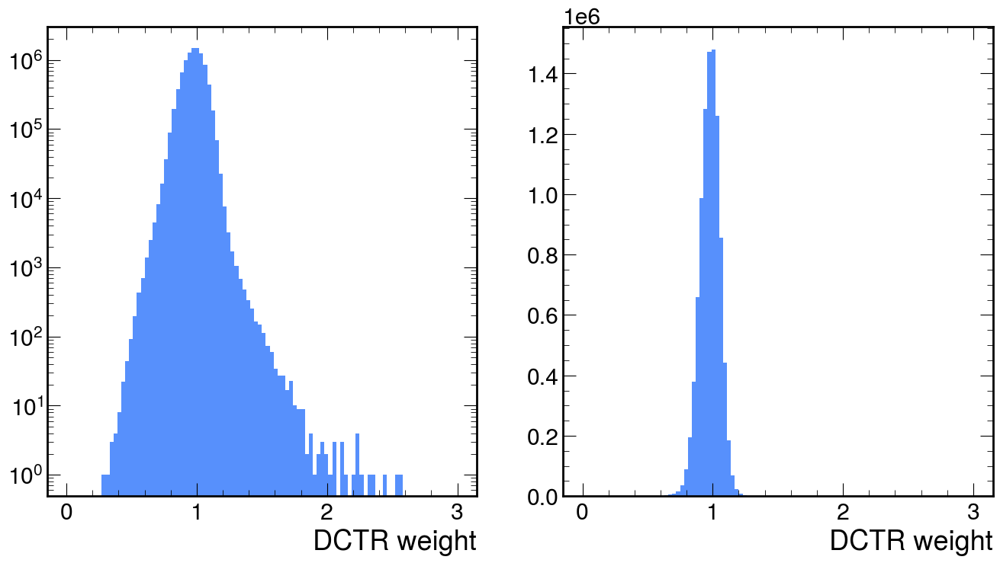

In [23]:
f, (ax, bx) = plt.subplots(1, 2, figsize=(16,8))
ax.hist(df.dctr_weight, bins=100, range=(0,3))
bx.hist(df.dctr_weight, bins=100,range=(0,3))
ax.set_yscale("log")
ax.set_xlabel("DCTR weight")
bx.set_xlabel("DCTR weight")
f.savefig(os.path.join(save_folder, "dctr_weight.png"),dpi=300)


In [25]:
# define all the masks
mask_mc = (df.data == 0)
is_data = (df.data == 1)

mask_signal = mask_mc & (df.tthbb == 1)
mask_ttbb = mask_mc & (df.ttbb == 1)
mask_ttcc = mask_mc & (df.ttcc == 1)
mask_ttlf = mask_mc & (df.ttlf == 1)
mask_singletop = mask_mc & (df.singletop == 1)
mask_otherbkg = mask_mc & ((df.vjets==1)|(df.ttv==1)|(df.vv==1))
mask_data_minus_minor_bkg = (df.dctr == 1)
masks_njet = {
    "4j": ak.num(df.JetGood) == 4,
    "5j": ak.num(df.JetGood) == 5,
    "6j": ak.num(df.JetGood) == 6,
    ">=7j": ak.num(df.JetGood) >= 7,
}

df.events = ak.with_field(df.events, df.BJetGood[:, 2].pt, "bjet_pt_3")
df.events = ak.with_field(df.events, ak.num(df.BJetGood), "nbjets")
df.events = ak.with_field(df.events, ak.num(df.JetGood), "njets")

In [27]:
# define signal and control region masks
isCR = get_cr_mask(df.spanet_output, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)
isSR = get_sr_mask(df.spanet_output, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)

In [30]:
hist_settings = {
    "ht" : (80, 0, 1200),
    "bjets_ht" : (80,0,1200),
    "lightjets_ht": (80, 0, 600),
    "drbb_min": (80, 0, 3),
    "mbb_closest": (80,50, 400),
    "bjet_pt_3": (80, 30, 200),
    "nbjets" : (4, 3,7),
    "njets": (6, 5, 10)
}

cols = [ "ht" , "lightjets_ht", "bjets_ht", "bjet_pt_3", "mbb_closest", "drbb_min"]#, "nbjets"]

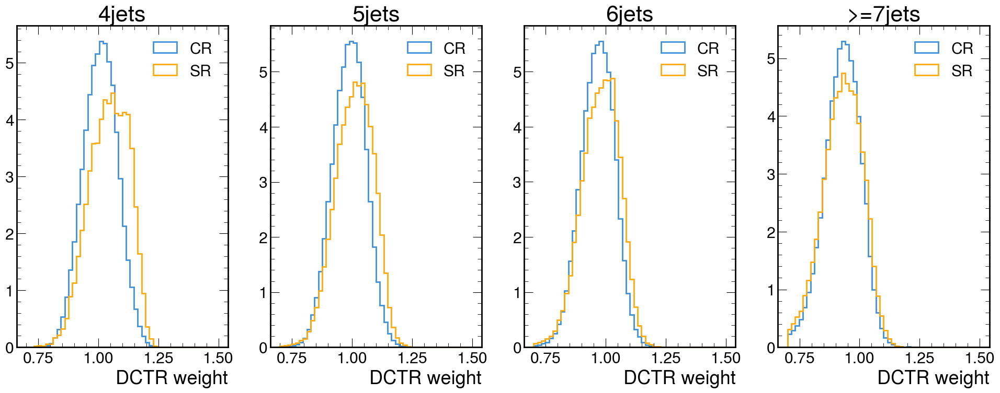

In [29]:
f, axs = plt.subplots(1, 4, figsize=(24,8))
axs[0].hist(df[mask_ttbb & (njet == 4) & isCR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[0], label="CR", density=True)
axs[0].hist(df[mask_ttbb & (njet == 4) & isSR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[1], label="SR", density=True)
axs[0].set_title("4jets")
axs[0].set_xlabel("DCTR weight")
axs[0].legend()

axs[1].hist(df[mask_ttbb & (njet == 5) & isCR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[0], label="CR", density=True)
axs[1].hist(df[mask_ttbb & (njet == 5) & isSR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[1], label="SR", density=True)
axs[1].set_title("5jets")
axs[1].set_xlabel("DCTR weight")
axs[1].legend()

axs[2].hist(df[mask_ttbb & (njet == 6) & isCR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[0], label="CR", density=True)
axs[2].hist(df[mask_ttbb & (njet == 6) & isSR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[1], label="SR", density=True)
axs[2].set_title("6jets")
axs[2].set_xlabel("DCTR weight")
axs[2].legend()

axs[3].hist(df[mask_ttbb & (njet >= 7) & isCR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[0], label="CR", density=True)
axs[3].hist(df[mask_ttbb & (njet >= 7) & isSR].dctr_weight, range=(0.7, 1.5), bins=50, histtype="step", linewidth=2, color=CMAP_10[1], label="SR", density=True)
axs[3].set_title(">=7jets")
axs[3].set_xlabel("DCTR weight")
axs[3].legend()
f.savefig(os.path.join(save_folder, "dctr_weight_by_njets_CR_SR.png"),dpi=300)

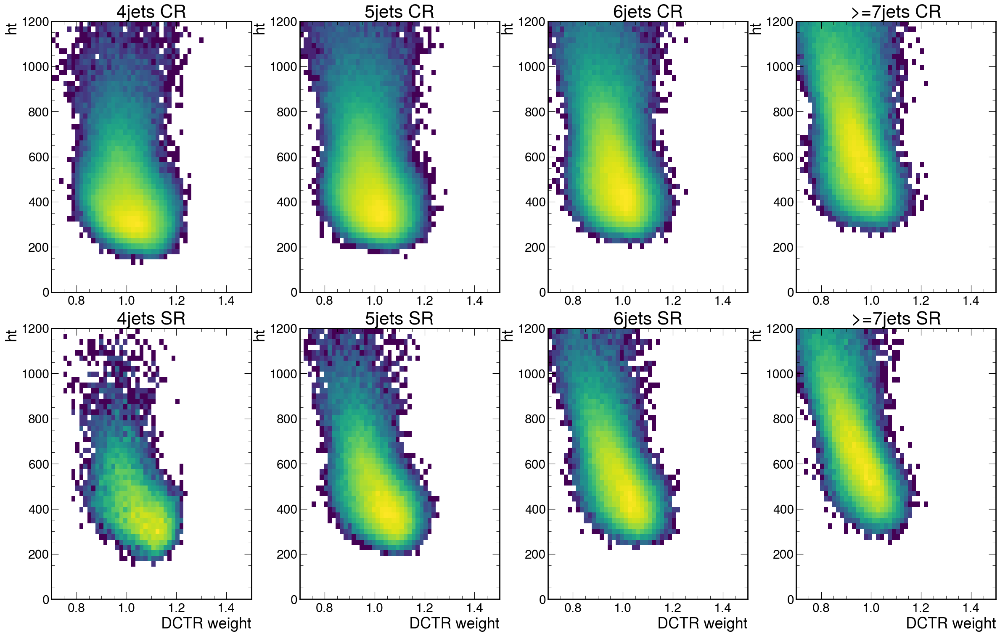

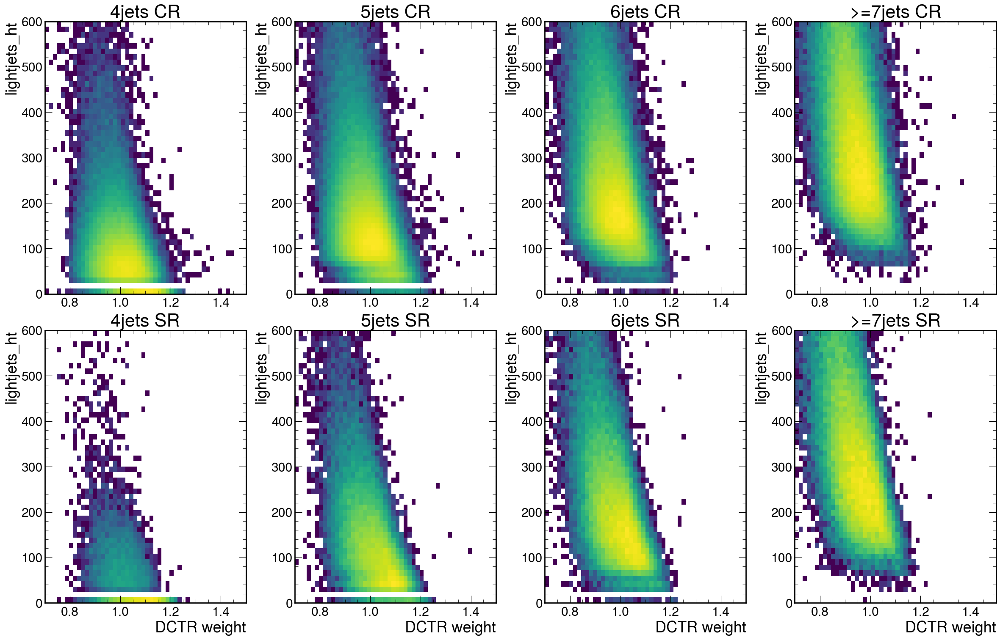

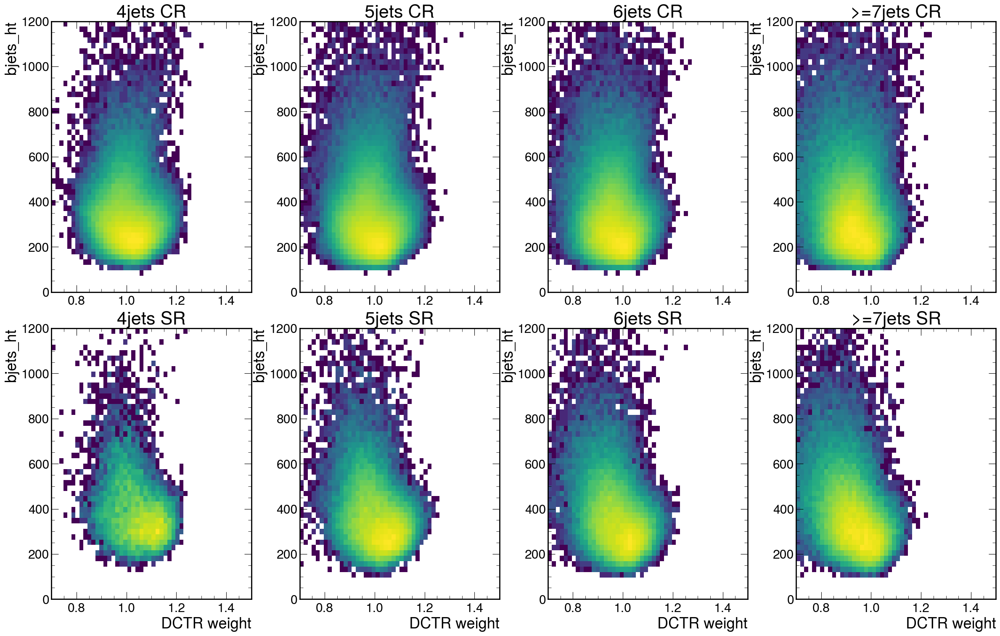

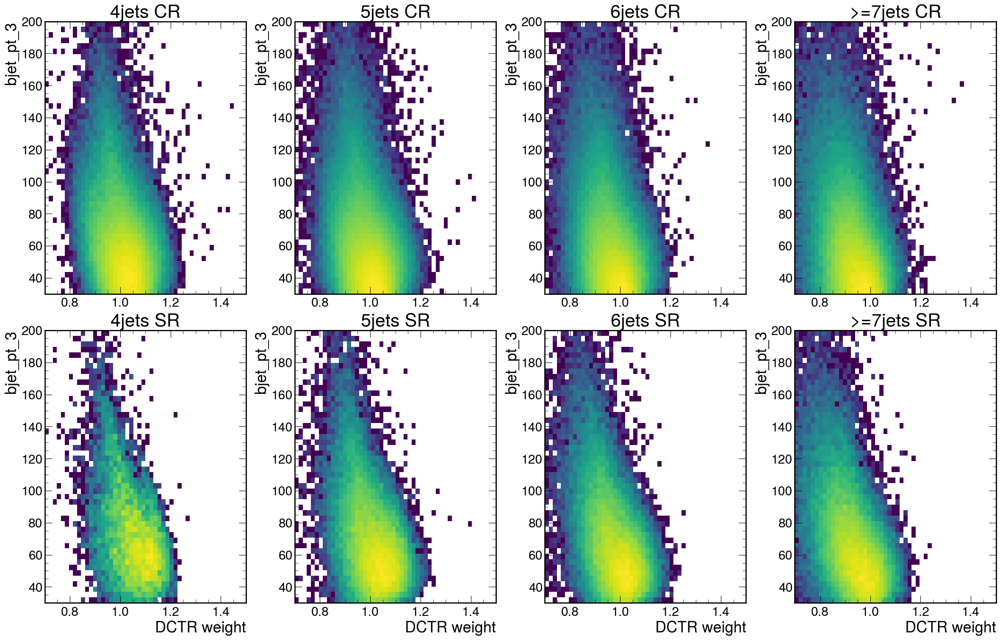

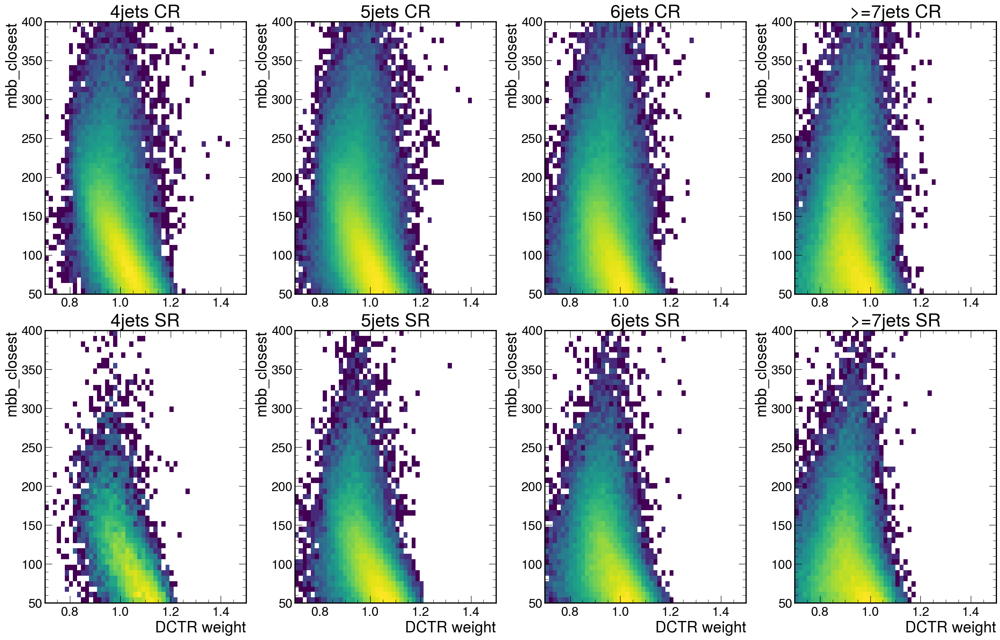

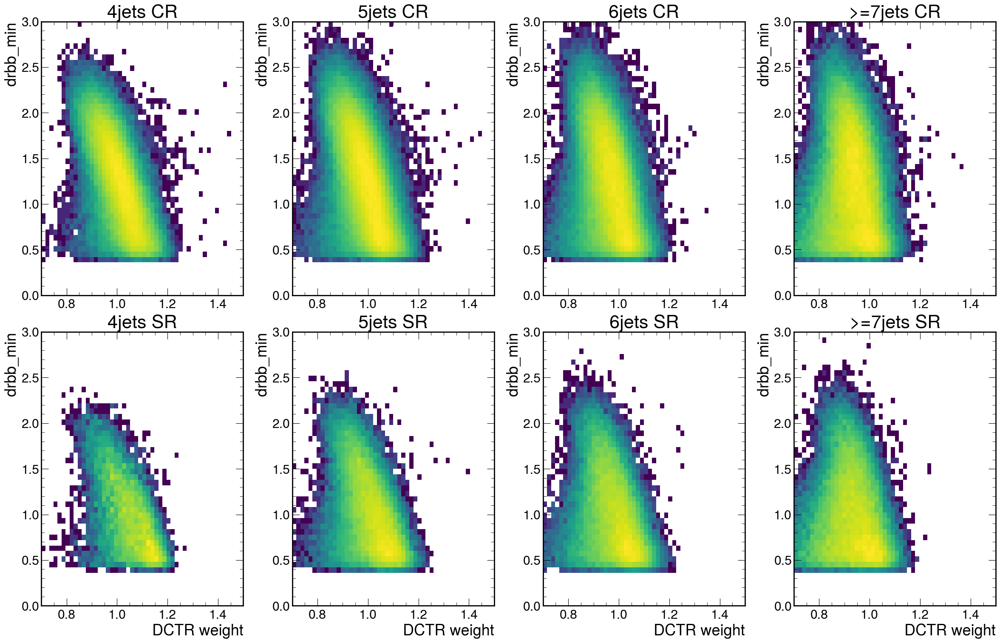

In [31]:
for col in cols:
    f, axs = plt.subplots(2, 4, figsize=(24, 15))
    plt.tight_layout()
    axs[0,0].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 4) & isCR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 4) & isCR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[0,0].set_title("4jets CR")
    #axs[0,0].set_xlabel("DCTR weight")
    axs[0,0].set_ylabel(col)

    axs[0,1].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 5) & isCR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 5) & isCR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[0,1].set_title("5jets CR")
    #axs[0,1].set_xlabel("DCTR weight")
    axs[0,1].set_ylabel(col)

    axs[0,2].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 6) & isCR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 6) & isCR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[0,2].set_title("6jets CR")
    #axs[0,2].set_xlabel("DCTR weight")
    axs[0,2].set_ylabel(col)

    axs[0,3].hist2d(ak.to_numpy(df[mask_ttbb & (njet >= 7) & isCR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet >= 7) & isCR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[0,3].set_title(">=7jets CR")
    #axs[0,3].set_xlabel("DCTR weight")
    axs[0,3].set_ylabel(col)

    axs[1,0].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 4) & isSR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 4) & isSR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[1,0].set_title("4jets SR")
    axs[1,0].set_xlabel("DCTR weight")
    axs[1,0].set_ylabel(col)

    axs[1,1].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 5) & isSR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 5) & isSR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[1,1].set_title("5jets SR")
    axs[1,1].set_xlabel("DCTR weight")
    axs[1,1].set_ylabel(col)

    axs[1,2].hist2d(ak.to_numpy(df[mask_ttbb & (njet == 6) & isSR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet == 6) & isSR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[1,2].set_title("6jets SR")
    axs[1,2].set_xlabel("DCTR weight")
    axs[1,2].set_ylabel(col)

    axs[1,3].hist2d(ak.to_numpy(df[mask_ttbb & (njet >= 7) & isSR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & (njet >= 7) & isSR]),
                  range=((0.7, 1.5), hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[1,3].set_title(">=7jets SR")
    axs[1,3].set_xlabel("DCTR weight")
    axs[1,3].set_ylabel(col)
    plt.savefig(save_folder+f'/dctr_vs_{col}_ttbb.png')

In [33]:
# Split events in 33% quantiles of the DCTR weight
q = [1./3, 2./3] 
weight_cut_bynjet = {}
for nj in range(4, 8):
    if nj == 7:
        mask_nj = ak.to_numpy(njet >= nj)
    else:
        mask_nj = ak.to_numpy(njet == nj)
    
    # Mask for ttbb events in ttbb_CR with specific njet
    mask_ttbb_nj = mask_nj & mask_ttbb & isCR
    weights_by_njet = ak.to_numpy(df.dctr_weight[mask_ttbb_nj])
    
    # Calculate quantiles
    w_lo, w_hi = np.quantile(weights_by_njet, q)
    
    if nj == 7:
        weight_cut_bynjet[f"njet>={nj}"] = [(0, w_lo), (w_lo, w_hi), (w_hi, 3)]
    else:
        weight_cut_bynjet[f"njet={nj}"] = [(0, w_lo), (w_lo, w_hi), (w_hi, 3)]

weight_cut_bynjet

{'njet=4': [(0, 0.9776800672213236),
  (0.9776800672213236, 1.041250745455424),
  (1.041250745455424, 3)],
 'njet=5': [(0, 0.9580705761909485),
  (0.9580705761909485, 1.0193914572397869),
  (1.0193914572397869, 3)],
 'njet=6': [(0, 0.9363475441932678),
  (0.9363475441932678, 0.9980140924453735),
  (0.9980140924453735, 3)],
 'njet>=7': [(0, 0.8969404101371765),
  (0.8969404101371765, 0.9622199734052023),
  (0.9622199734052023, 3)]}

In [35]:
njet = ak.num(df.JetGood)
dctr_regions = {
    "4j_L":  (njet == 4)&(df.dctr_weight >= weight_cut_bynjet["njet=4"][0][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=4"][0][1]),
    "4j_M":  (njet == 4)&(df.dctr_weight >= weight_cut_bynjet["njet=4"][1][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=4"][1][1]),
    "4j_H":  (njet == 4)&(df.dctr_weight >= weight_cut_bynjet["njet=4"][2][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=4"][2][1]),

    "5j_L":  (njet == 5)&(df.dctr_weight >= weight_cut_bynjet["njet=5"][0][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=5"][0][1]),
    "5j_M":  (njet == 5)&(df.dctr_weight >= weight_cut_bynjet["njet=5"][1][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=5"][1][1]),
    "5j_H":  (njet == 5)&(df.dctr_weight >= weight_cut_bynjet["njet=5"][2][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=5"][2][1]),
    
    "6j_L":  (njet == 6)&(df.dctr_weight >= weight_cut_bynjet["njet=6"][0][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=6"][0][1]),
    "6j_M":  (njet == 6)&(df.dctr_weight >= weight_cut_bynjet["njet=6"][1][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=6"][1][1]),
    "6j_H":  (njet == 6)&(df.dctr_weight >= weight_cut_bynjet["njet=6"][2][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet=6"][2][1]),

    ">=7j_L":  (njet > 6)&(df.dctr_weight >= weight_cut_bynjet["njet>=7"][0][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet>=7"][0][1]),
    ">=7j_M":  (njet > 6)&(df.dctr_weight >= weight_cut_bynjet["njet>=7"][1][0])&\
                         (df.dctr_weight < weight_cut_bynjet["njet>=7"][1][1]),
    ">=7j_H":  (njet > 6)&(df.dctr_weight >= weight_cut_bynjet["njet>=7"][2][0])&\
                            (df.dctr_weight < weight_cut_bynjet["njet>=7"][2][1]),
}
          

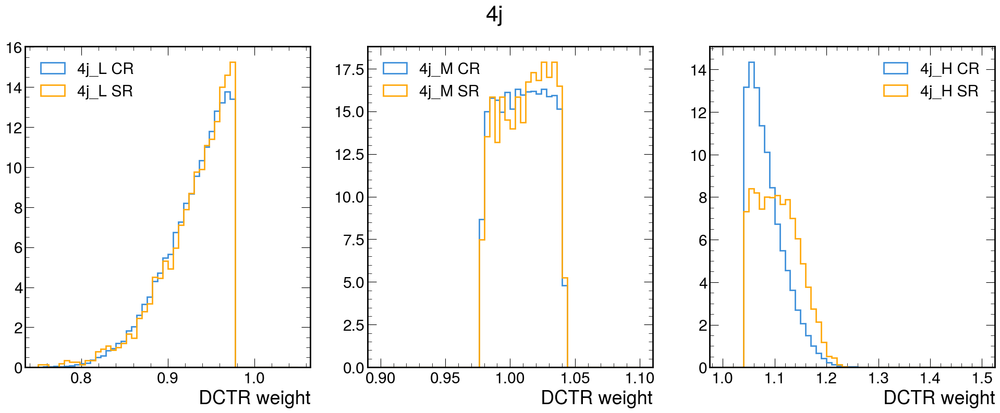

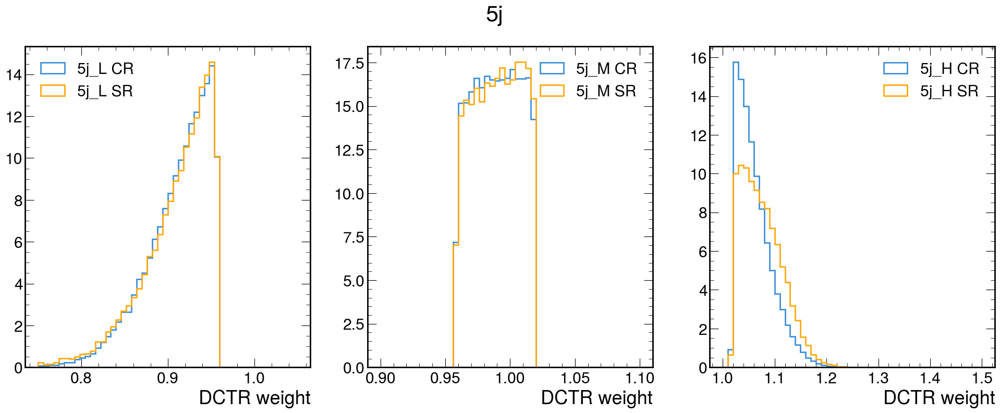

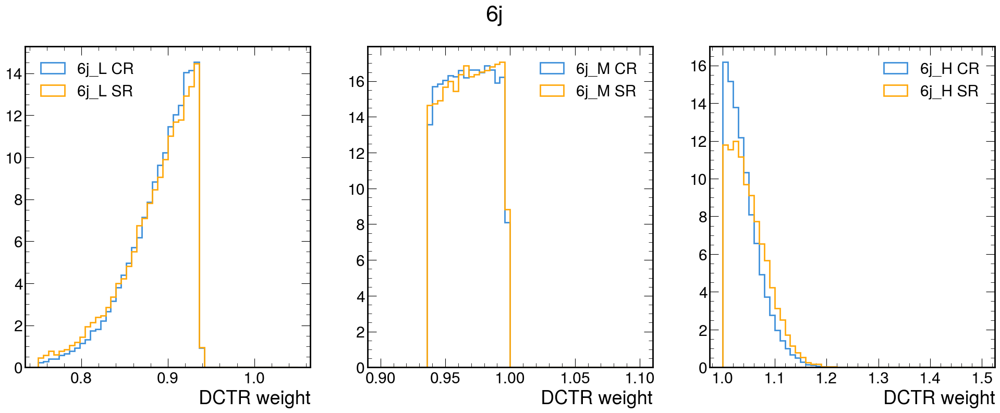

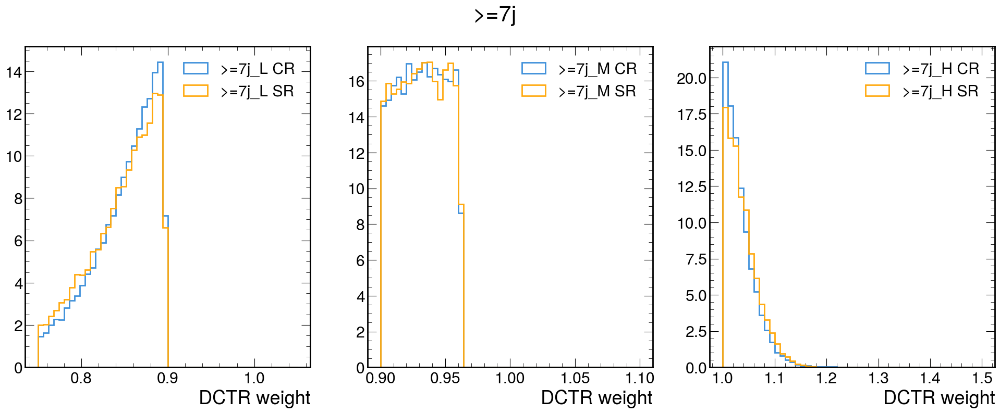

In [39]:
# dctr weight by nquantiles
dctr_ranges= [[0.75, 1.05],[0.9, 1.1], [ 1,1.5]]

for njets in ["4j","5j","6j", ">=7j"]:
    f, (ax, bx, cx ) = plt.subplots(1, 3, figsize=(24,8))
    ax.hist(df[mask_ttbb & dctr_regions[f"{njets}_L"] & isCR].dctr_weight, range=dctr_ranges[0], bins=50,histtype="step", linewidth=2, color=CMAP_10[0], label=f"{njets}_L CR", density=True )
    ax.hist(df[mask_ttbb & dctr_regions[f"{njets}_L"] & isSR].dctr_weight, range=dctr_ranges[0], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label=f"{njets}_L SR", density=True  )
    bx.hist(df[mask_ttbb & dctr_regions[f"{njets}_M"] & isCR].dctr_weight, range=dctr_ranges[1], bins=50,histtype="step", linewidth=2, color=CMAP_10[0],label=f"{njets}_M CR", density=True  )
    bx.hist(df[mask_ttbb & dctr_regions[f"{njets}_M"] & isSR].dctr_weight, range=dctr_ranges[1], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label=f"{njets}_M SR", density=True  )
    cx.hist(df[mask_ttbb & dctr_regions[f"{njets}_H"] & isCR].dctr_weight, range=dctr_ranges[2], bins=50,histtype="step", linewidth=2, color=CMAP_10[0], label=f"{njets}_H CR", density=True  )
    cx.hist(df[mask_ttbb & dctr_regions[f"{njets}_H"] & isSR].dctr_weight, range=dctr_ranges[2], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label=f"{njets}_H SR", density=True  )
    ax.set_xlabel("DCTR weight")
    bx.set_xlabel("DCTR weight")
    cx.set_xlabel("DCTR weight")
    ax.legend()
    bx.legend()
    cx.legend()
    f.suptitle(f"{njets}", fontsize="large")
    f.savefig(os.path.join(save_folder, f"dctr_weight_{njets}_quantiles_CR_SR.png"),dpi=300)

In [40]:
def plot_comparison_SR_DR(variable, njets, mask, output_folder, text="", density=True, apply_weight=False):
    f, (ax, bx, cx,r1x, r2x) = plt.subplots(1, 5, figsize=(40,8))
    nbins, range0, range1 = hist_settings[variable]
    ax.hist(df.events[variable][mask & dctr_regions[f"{njets}_L"] & isCR], bins=nbins, density=density, range=(range0,range1),
                            label="CR", color=CMAP_10[0],  histtype="step", linewidth=2,
           weights= weights[mask & dctr_regions[f"{njets}_L"] & isCR]);
    bx.hist(df.events[variable][mask & dctr_regions[f"{njets}_M"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                        label="CR", color=CMAP_10[0], histtype="step", linewidth=2,
           weights= weights[mask & dctr_regions[f"{njets}_M"] & isCR]);
    cx.hist(df.events[variable][mask & dctr_regions[f"{njets}_H"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                          label="CR", color=CMAP_10[0], histtype="step", linewidth=2,
              weights= weights[mask & dctr_regions[f"{njets}_H"] & isCR]);
    
    ax.hist(df.events[variable][mask & dctr_regions[f"{njets}_L"] & isSR], bins=nbins, density=density, range=(range0,range1),
                           label="SR", color=CMAP_10[1],  histtype="step", linewidth=2.,
            weights= weights[mask & dctr_regions[f"{njets}_L"] & isSR]);
    bx.hist(df.events[variable][mask & dctr_regions[f"{njets}_M"]& isSR], bins=nbins, density=density, range=(range0,range1),
                            label="SR", color=CMAP_10[1], histtype="step", linewidth=2,
                        weights= weights[mask & dctr_regions[f"{njets}_M"] & isSR]);
    cx.hist(df.events[variable][mask & dctr_regions[f"{njets}_H"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                          label="SR", color=CMAP_10[1], histtype="step", linewidth=2,
            weights= weights[mask & dctr_regions[f"{njets}_H"] &isSR]);

    r1x.hist(df.events[variable][mask & dctr_regions[f"{njets}_L"] & isCR], bins=nbins, density=density, range=(range0,range1),
                            label="L", color=CMAP_10[0], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions[f"{njets}_L"] & isCR]);
    r1x.hist(df.events[variable][mask & dctr_regions[f"{njets}_M"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                        label="M", color=CMAP_10[1], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions[f"{njets}_M"] & isCR]);
    r1x.hist(df.events[variable][mask & dctr_regions[f"{njets}_H"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                          label="H", color=CMAP_10[2], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions[f"{njets}_H"] & isCR]);

    r2x.hist(df.events[variable][mask & dctr_regions[f"{njets}_L"] & isSR], bins=nbins, density=density, range=(range0,range1),
                            label="L", color=CMAP_10[0], histtype="step", linewidth=2,
                    weights= weights[mask & dctr_regions[f"{njets}_L"] & isSR]);
    r2x.hist(df.events[variable][mask & dctr_regions[f"{njets}_M"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                        label="M", color=CMAP_10[1], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions[f"{njets}_M"] & isSR]);
    r2x.hist(df.events[variable][mask & dctr_regions[f"{njets}_H"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                          label="H", color=CMAP_10[2], histtype="step", linewidth=2,
              weights= weights[mask & dctr_regions[f"{njets}_H"] & isSR]);

    ax.set_xlabel(variable)
    bx.set_xlabel(variable)
    cx.set_xlabel(variable)
    r1x.set_xlabel(variable)
    r2x.set_xlabel(variable)
    ax.set_title("DCTR Low", fontsize="small")
    bx.set_title("DCTR Medium", fontsize="small")
    cx.set_title("DCTR High", fontsize="small")
    r1x.set_title("CR comparison", fontsize="small")
    r2x.set_title("SR comparison", fontsize="small")
    ax.legend()
    bx.legend()
    cx.legend()
    r1x.legend()
    r2x.legend()
    f.suptitle(f"{text}: {njets}", fontsize="large")
    plt.tight_layout()
    plt.savefig(f"{output_folder}/dctr_shape_comparison_{variable}_{njets}_{text}.pdf")
    plt.savefig(f"{output_folder}/dctr_shape_comparison_{variable}_{njets}_{text}.png")
    plt.show()
    plt.close()

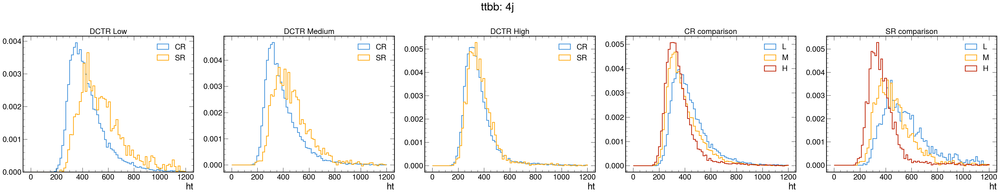

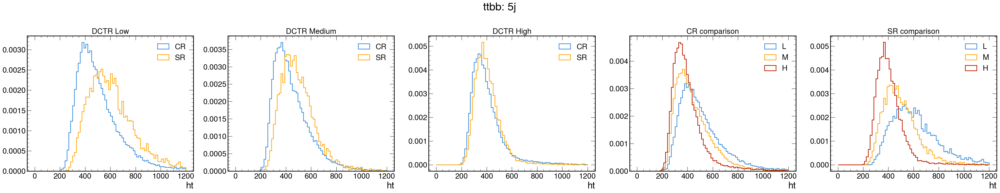

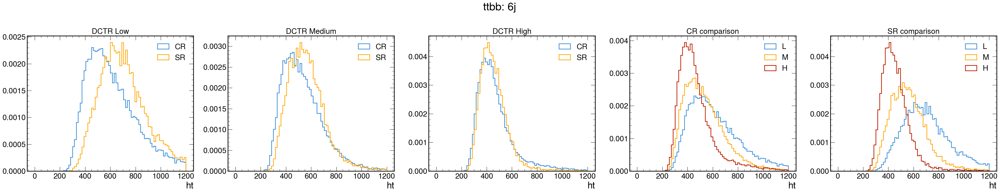

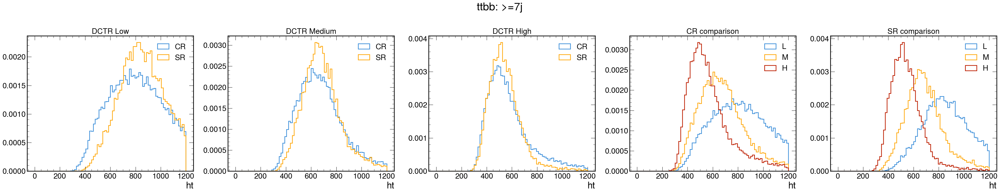

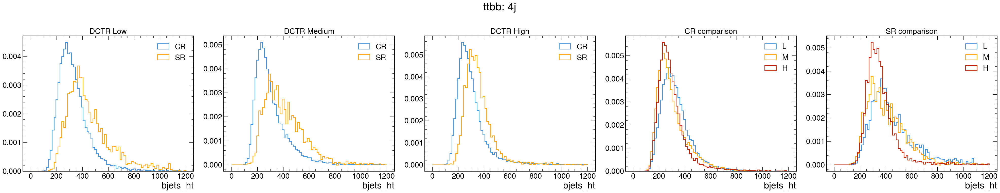

...

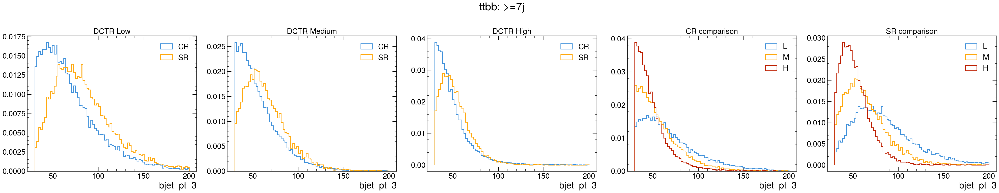

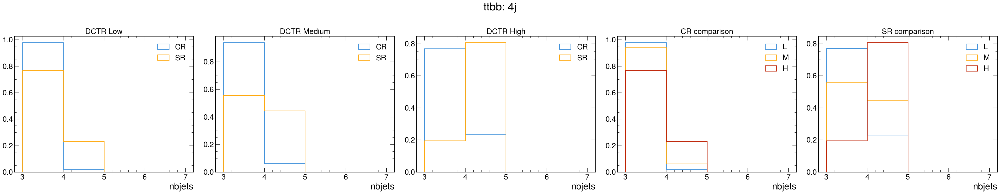

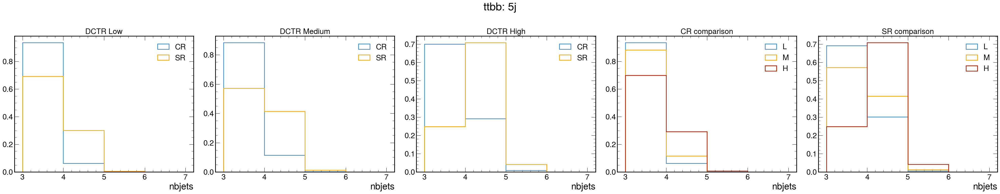

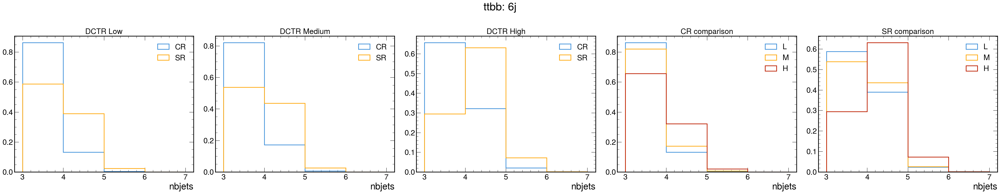

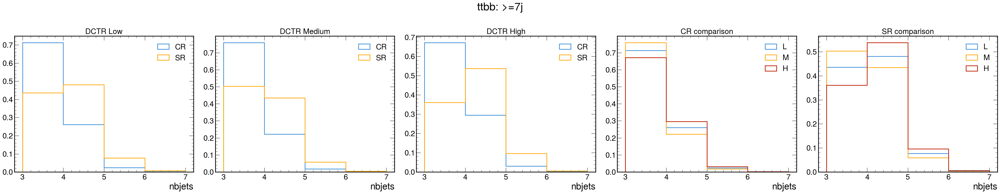

/afs/cern.ch/work/g/gbonomel/envs/jupy/lib/python3.11/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


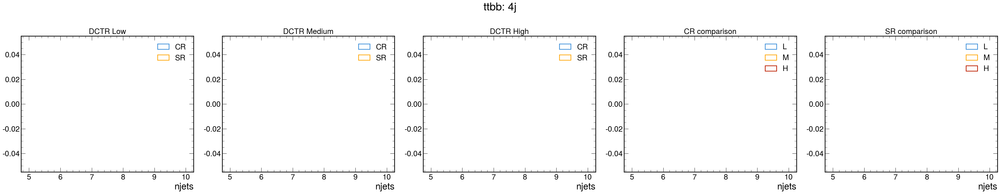

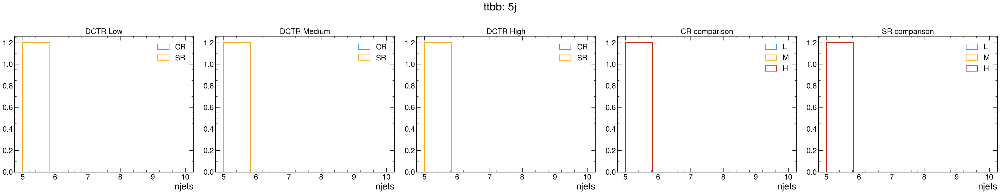

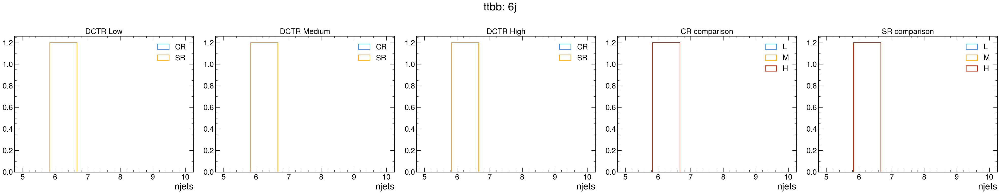

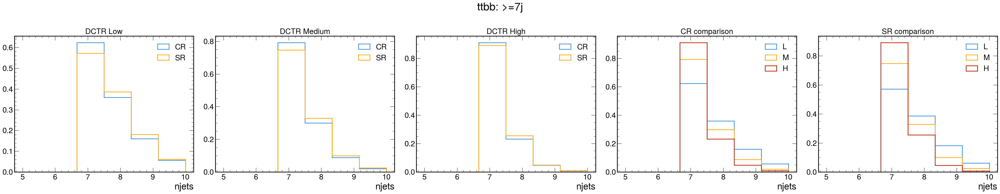

In [41]:
for variable in hist_settings.keys():
    for njets in ["4j","5j","6j", ">=7j"]:
        plot_comparison_SR_DR(variable, njets, mask_ttbb,  text="ttbb", output_folder=save_folder, density=True)

In [44]:
def plot_corr_corner(cols, ranges, bins, colors, initial_mask,title, output_folder, legloc="upper right", nlevels=5, bins_contour=15):
    for njets in ["4j","5j","6j", ">=7j"]:
        f, axs = plt.subplots(len(cols), len(cols), figsize=(6*len(cols), 6*len(cols)), dpi=70)
        
        mask_L = initial_mask & dctr_regions[f"{njets}_L"]
        mask_H = initial_mask & dctr_regions[f"{njets}_H"]
        mask_M = initial_mask & dctr_regions[f"{njets}_M"]

        for ic in range(len(cols)):
            for jc in range(len(cols)):
                if ic == jc:
                    axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_L]),
                                     weights=ak.to_numpy(weights[mask_L]),
                                     bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                    label="L", color=colors["L"], density=True)
                    axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_M]),
                                     weights=ak.to_numpy(weights[mask_M]),
                                     bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                    label="M",color=colors["M"], density=True)
                    axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_H]),
                                     weights=ak.to_numpy(weights[mask_H]),
                                     bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                    label="H",color=colors["H"], density=True)
                    if jc == len(cols)-1:
                         axs[ic][jc].set_xlabel(cols[ic])
                    if ic == 0:
                        axs[ic][jc].set_ylabel(cols[ic])
                    axs[ic][jc].legend()
                
                # elif jc > ic:
                #     axs[ic][jc].remove()
                #     continue
                
                else:
                    col1 = cols[jc]
                    col2 = cols[ic]
                    histL, xedges, yedges = np.histogram2d(  
                                    ak.to_numpy(df.events[col1][mask_L]),
                                    ak.to_numpy(df.events[col2][mask_L]), 
                                    weights = ak.to_numpy(weights[mask_L]),
                                   bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                    density=True)
                    
                    histM, xedges, yedges = np.histogram2d(  
                                    ak.to_numpy(df.events[col1][mask_M]),
                                    ak.to_numpy(df.events[col2][mask_M]), 
                                    weights = ak.to_numpy(weights[mask_M]),
                                   bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                    density=True)
                    
                    histH, xedges, yedges = np.histogram2d(  
                                    ak.to_numpy(df.events[col1][mask_H]),
                                    ak.to_numpy(df.events[col2][mask_H]), 
                                    weights = ak.to_numpy(weights[mask_H]),
                                   bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                    density=True)
                    
                    x_centers = (xedges[:-1] + xedges[1:]) / 2
                    y_centers = (yedges[:-1] + yedges[1:]) / 2
                    X, Y = np.meshgrid(x_centers, y_centers)
                    
                    CS1 = axs[ic][jc].contour(X, Y, histL.T, nlevels,colors="blue") #L
                    CS2 = axs[ic][jc].contour(X, Y, histM.T, nlevels, colors="black") #M
                    CS3 = axs[ic][jc].contour(X, Y, histH.T, nlevels,colors="red")  #H
            
                    plt.clabel(CS1, inline=True, fontsize=8, fmt='%1.0f')
                    plt.clabel(CS2, inline=True, fontsize=8, fmt='%1.0f')
                    plt.clabel(CS3, inline=True, fontsize=8, fmt='%1.0f')
                    
                    legend_elements = [
                        Line2D([0], [0], color='blue', label='L'),
                        Line2D([0], [0], color='black',  label='M'),
                        Line2D([0], [0], color='red', label='H')
                    ]
                    axs[ic][jc].legend(handles=legend_elements, loc=legloc)
                    
                    if jc == 0:
                        axs[ic][jc].set_ylabel(col2)
                    if ic == len(cols)-1:
                        axs[ic][jc].set_xlabel(col1)
           
        f.suptitle(f"{title}: {njets}", fontsize="large")
        plt.tight_layout()
        if output_folder:
            os.makedirs(output_folder, exist_ok=True)
            plt.savefig(f"{output_folder}/dctr_cornerplot_{title}_{njets}.pdf")
            #plt.savefig(f"{output_folder}/dctr_cornerplot_{title}_{njets}.png")

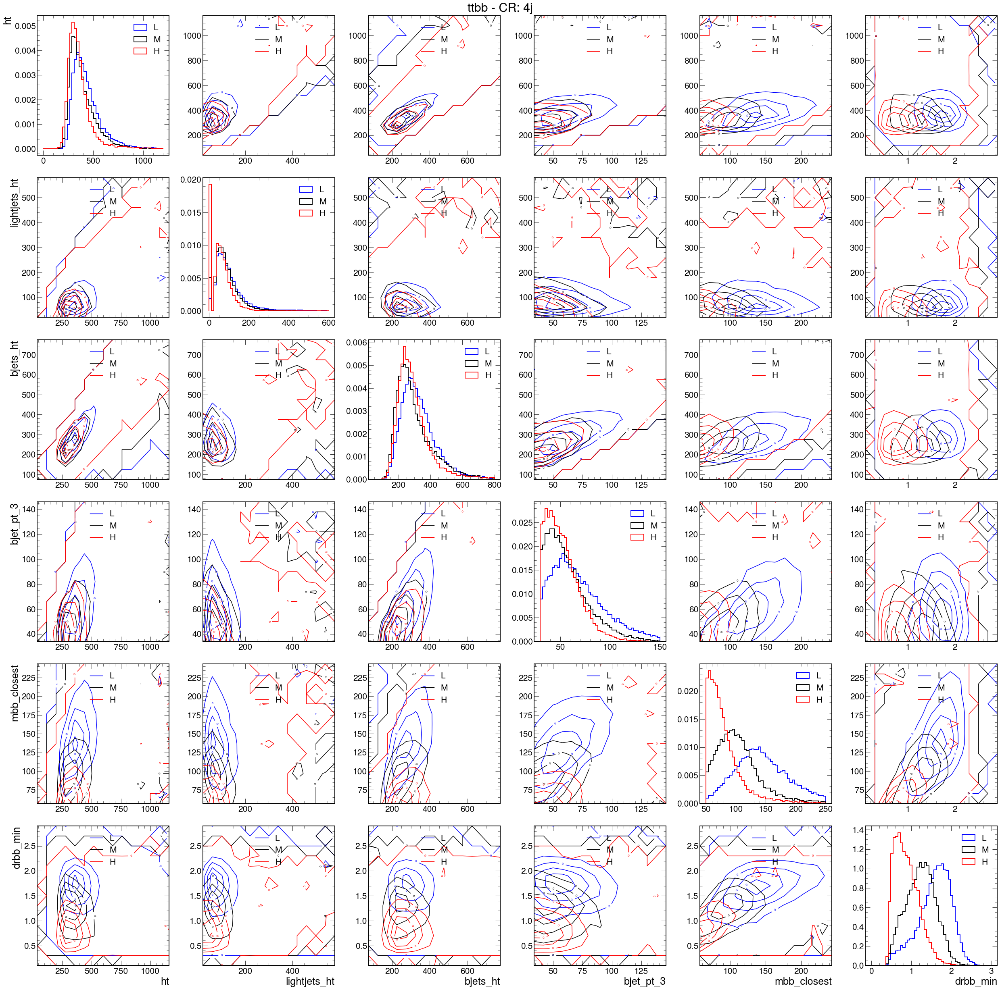

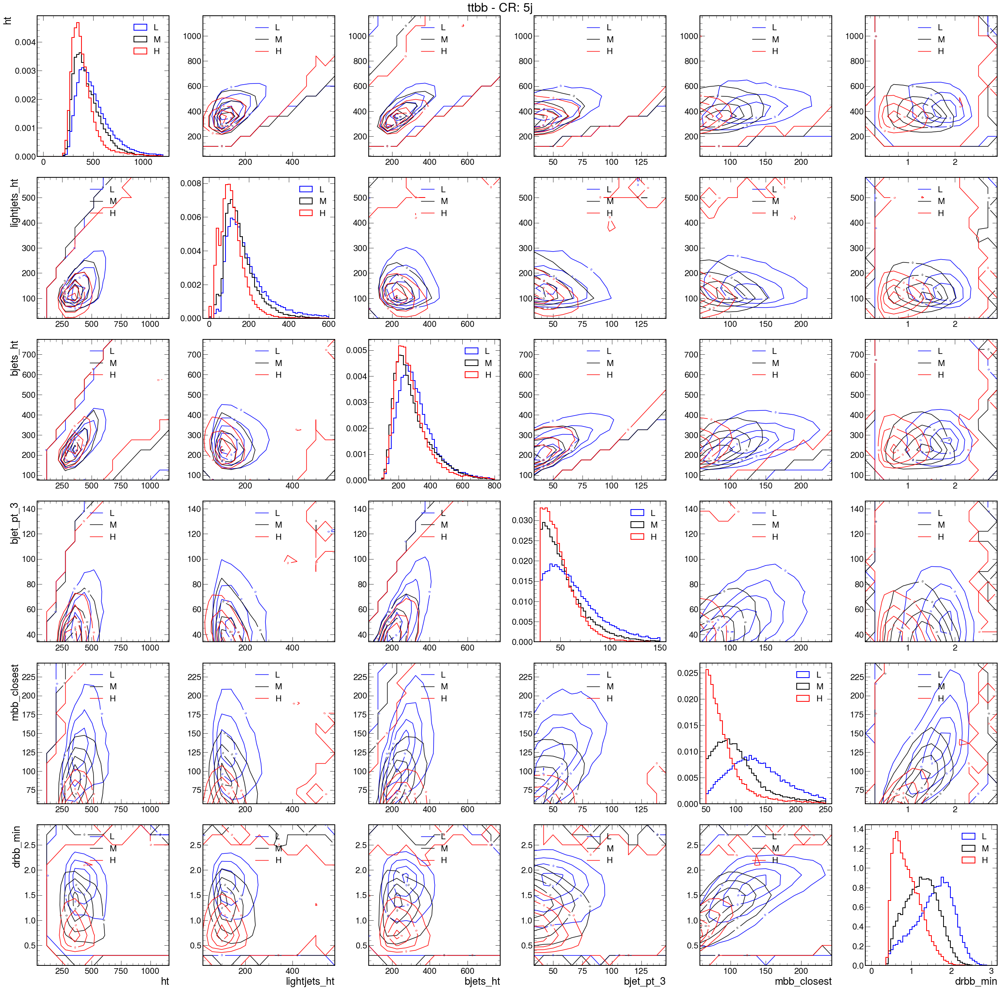

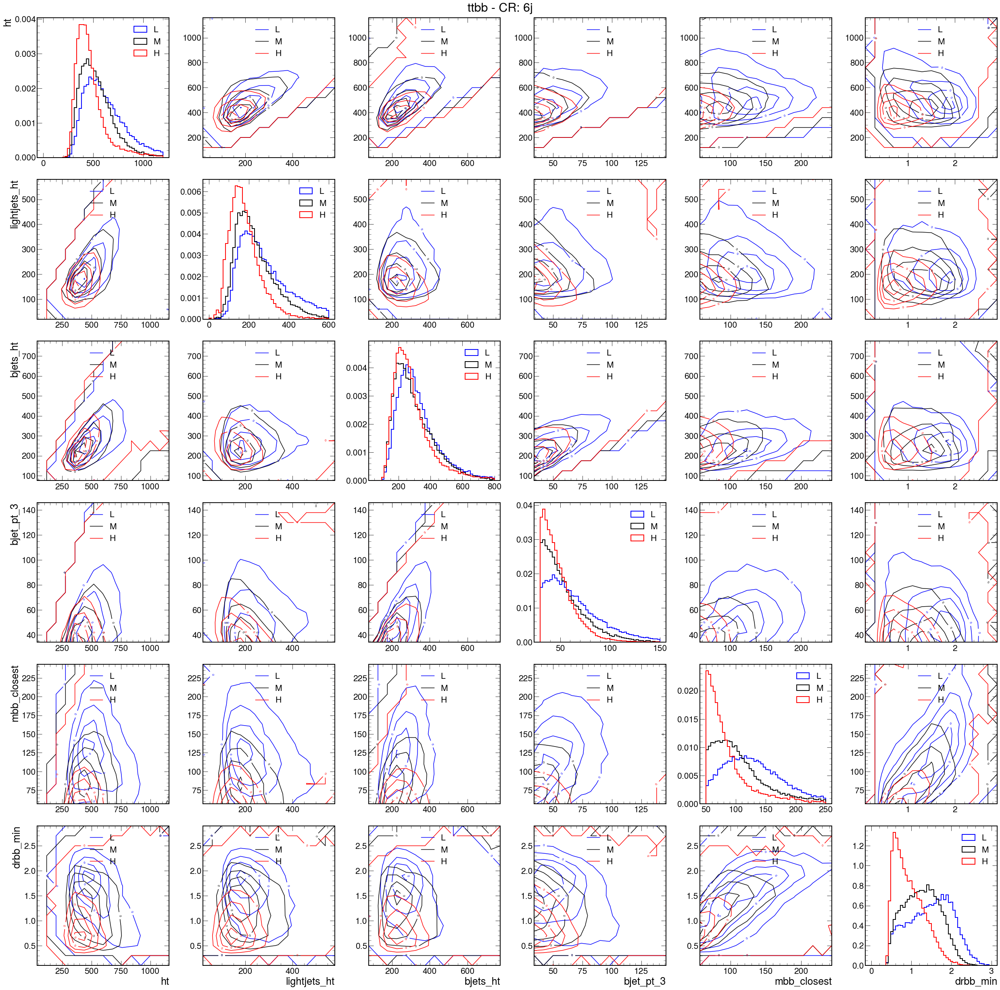

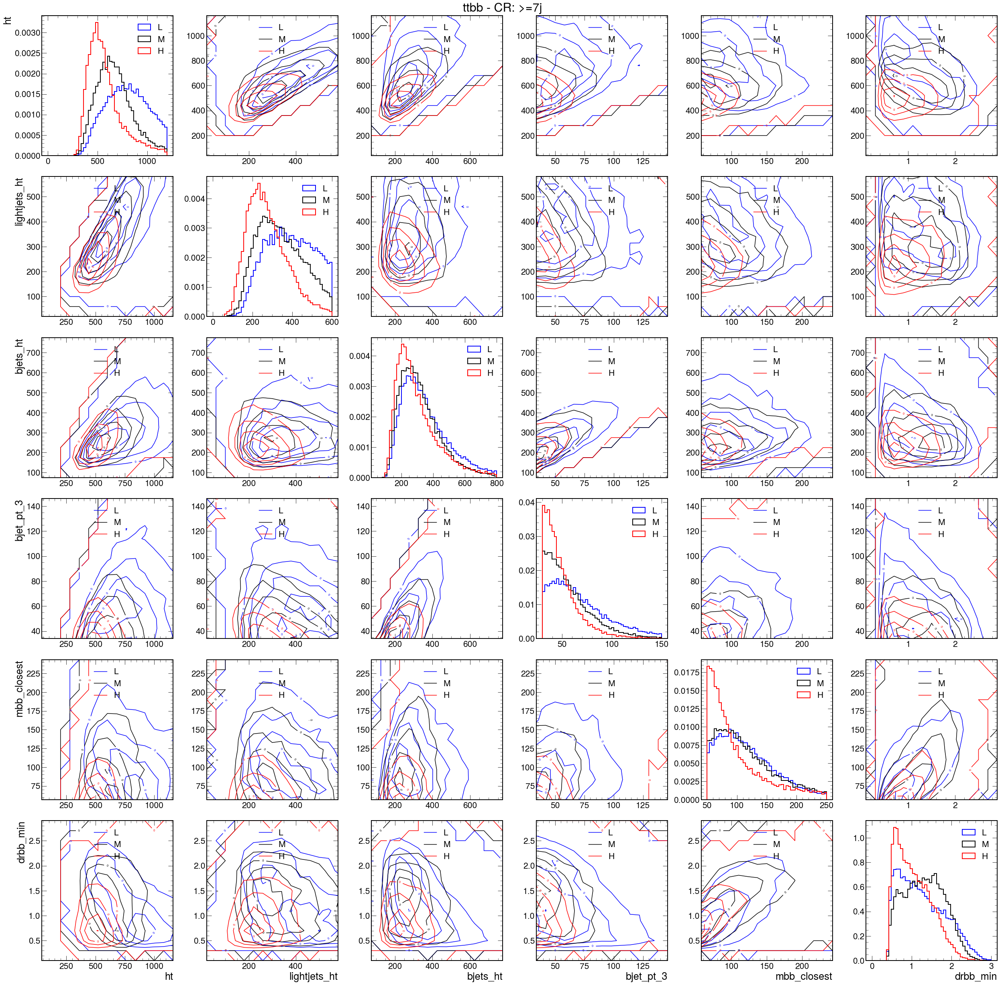

In [45]:
hist_settings_2 = {
    "ht" : (50, 0, 1200),
    "bjets_ht" : (50,50,800),
    "lightjets_ht": (50, 0, 600),
    "drbb_min": (50, 0, 3),
    "mbb_closest": (50,50, 250),
    "bjet_pt_3": (50, 30, 150),
}
columns_to_plot = [ k for k in cols if k not in["nbjets"]]
ranges= [hist_settings_2[k][1:] for k in columns_to_plot]
bins = [hist_settings_2[k][0] for k in columns_to_plot]
colors = {"H":"red","M":"black", "L":"blue"}

plot_corr_corner(columns_to_plot, ranges, bins, colors, initial_mask=(mask_ttbb&isCR), legloc="upper center", title="ttbb - CR", nlevels=4, bins_contour=15, output_folder=save_folder)


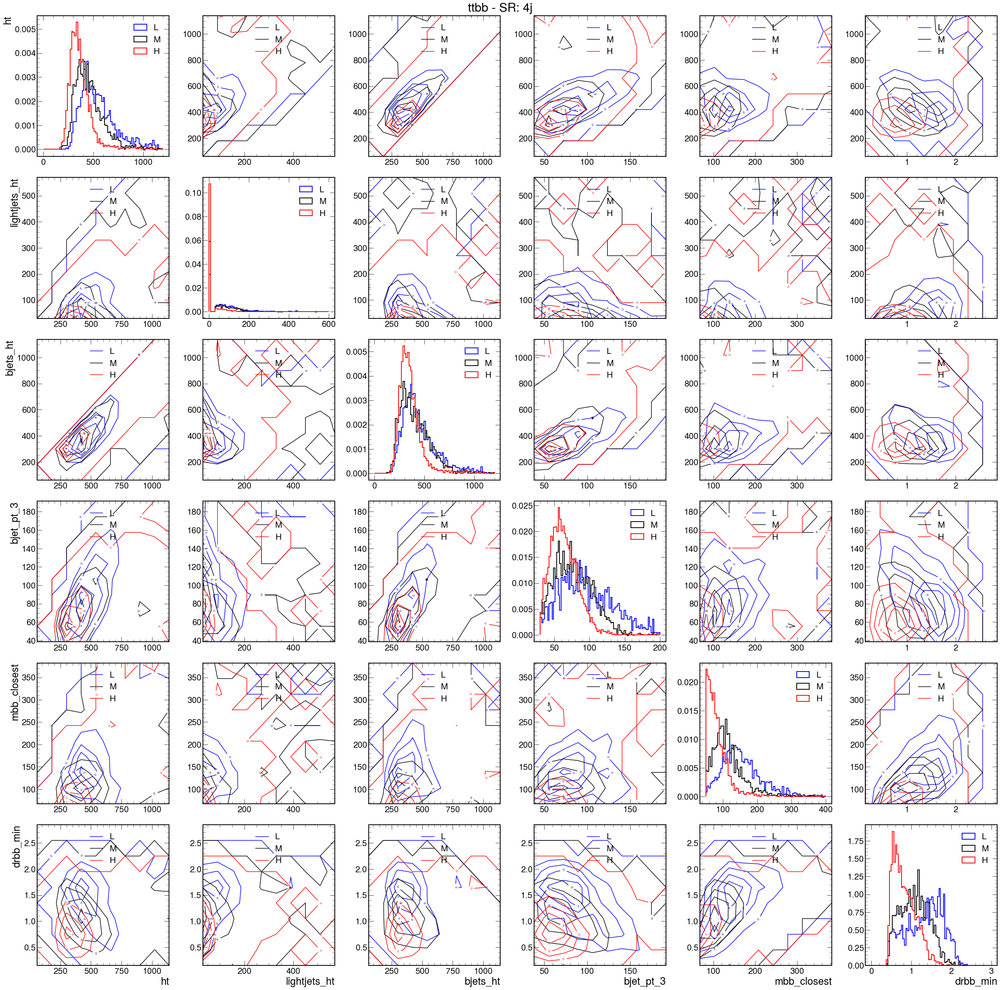

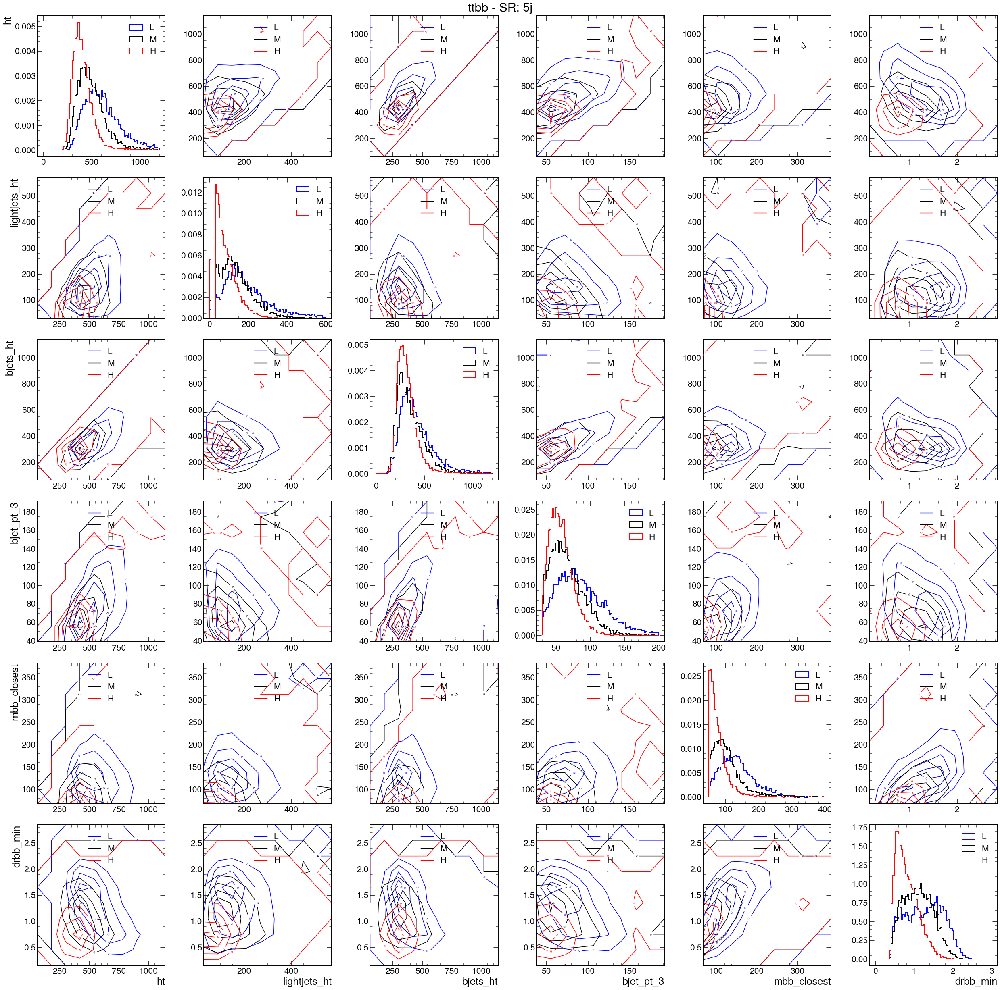

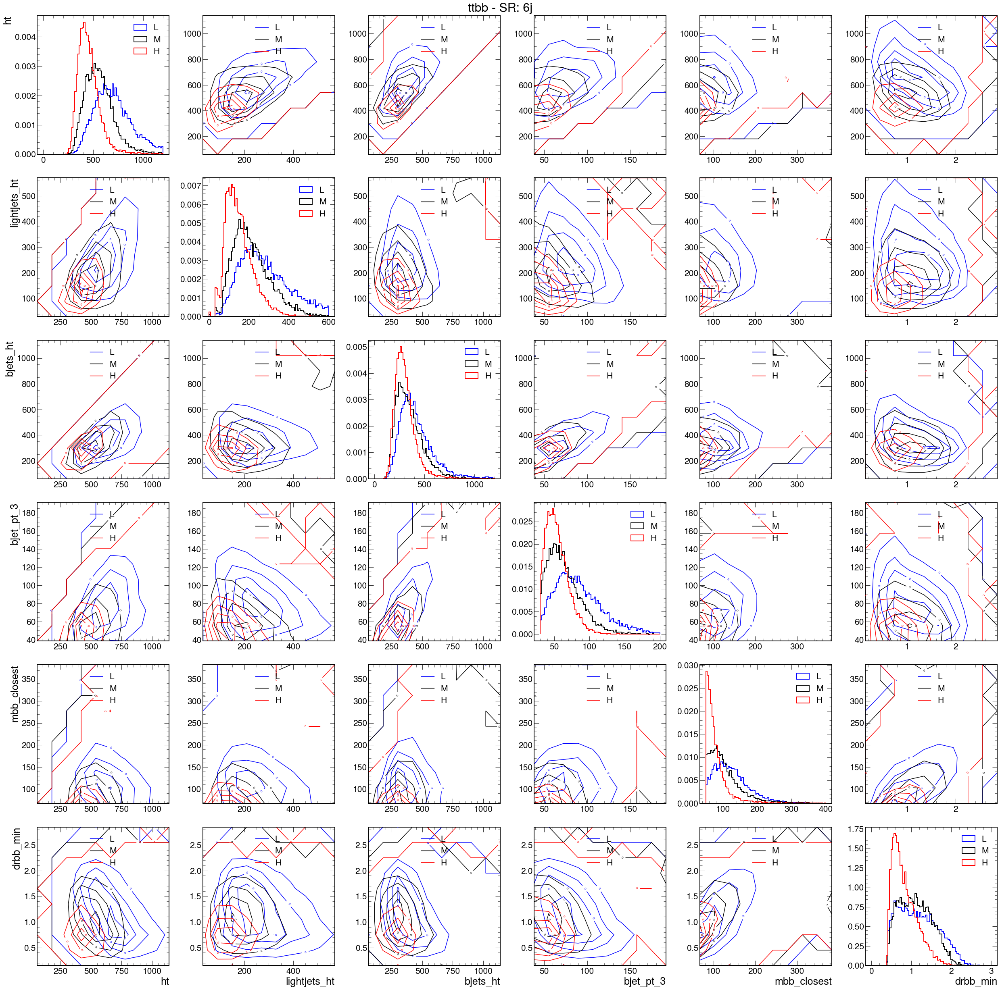

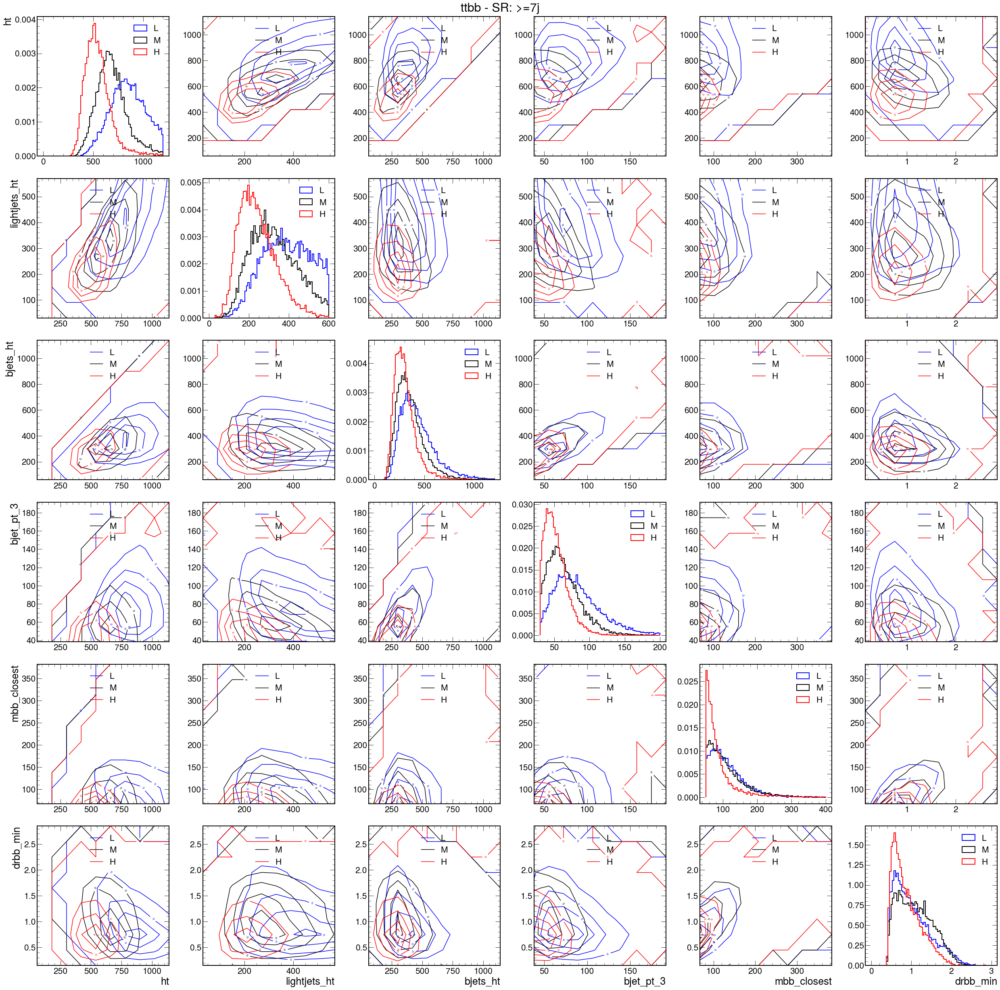

In [46]:
hist_settings_2 = {
    "ht" : (30, 0, 1200),
    "bjets_ht" : (30,50,800),
    "lightjets_ht": (30, 0, 600),
    "drbb_min": (30, 0, 3),
    "mbb_closest": (30,50, 250),
    "bjet_pt_3": (30, 30, 150),
}
columns_to_plot = [ k for k in cols if k not in["nbjets"]]
ranges= [hist_settings[k][1:] for k in columns_to_plot]
bins = [hist_settings[k][0] for k in columns_to_plot]
colors = {"H":"red","M":"black", "L":"blue"}

plot_corr_corner(columns_to_plot, ranges, bins, colors, initial_mask=(mask_ttbb&isSR), legloc="upper center", title="ttbb - SR", nlevels=4, bins_contour=10, output_folder=save_folder)